## Multi-Courier Pickup Conditions and Completion (Flag 8)

### Dataset Overview
This case follows LaDe-P pickup semantics for acceptance time, explicit time-window start/end, pickup time, and acceptance/pickup GPS positions. It provides five couriers, 75 accepted pickup tasks, and task-linked GPS segments. The compact sample is for analysis.

The notebook exposes a primary table and a supporting table (`courier_trajectories.csv`).

Goal: Analyze how task conditions and operational constraints affect pickup completion across the supplied trajectories and accepted pickup tasks from multiple couriers.

Role: Last-mile pickup operations analyst


Category: pickup task constraints, time-window compliance, and GPS travel distance

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "pickup_tasks.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does accepting a pickup task before versus after its promised service window begins relate to early pickup completion?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

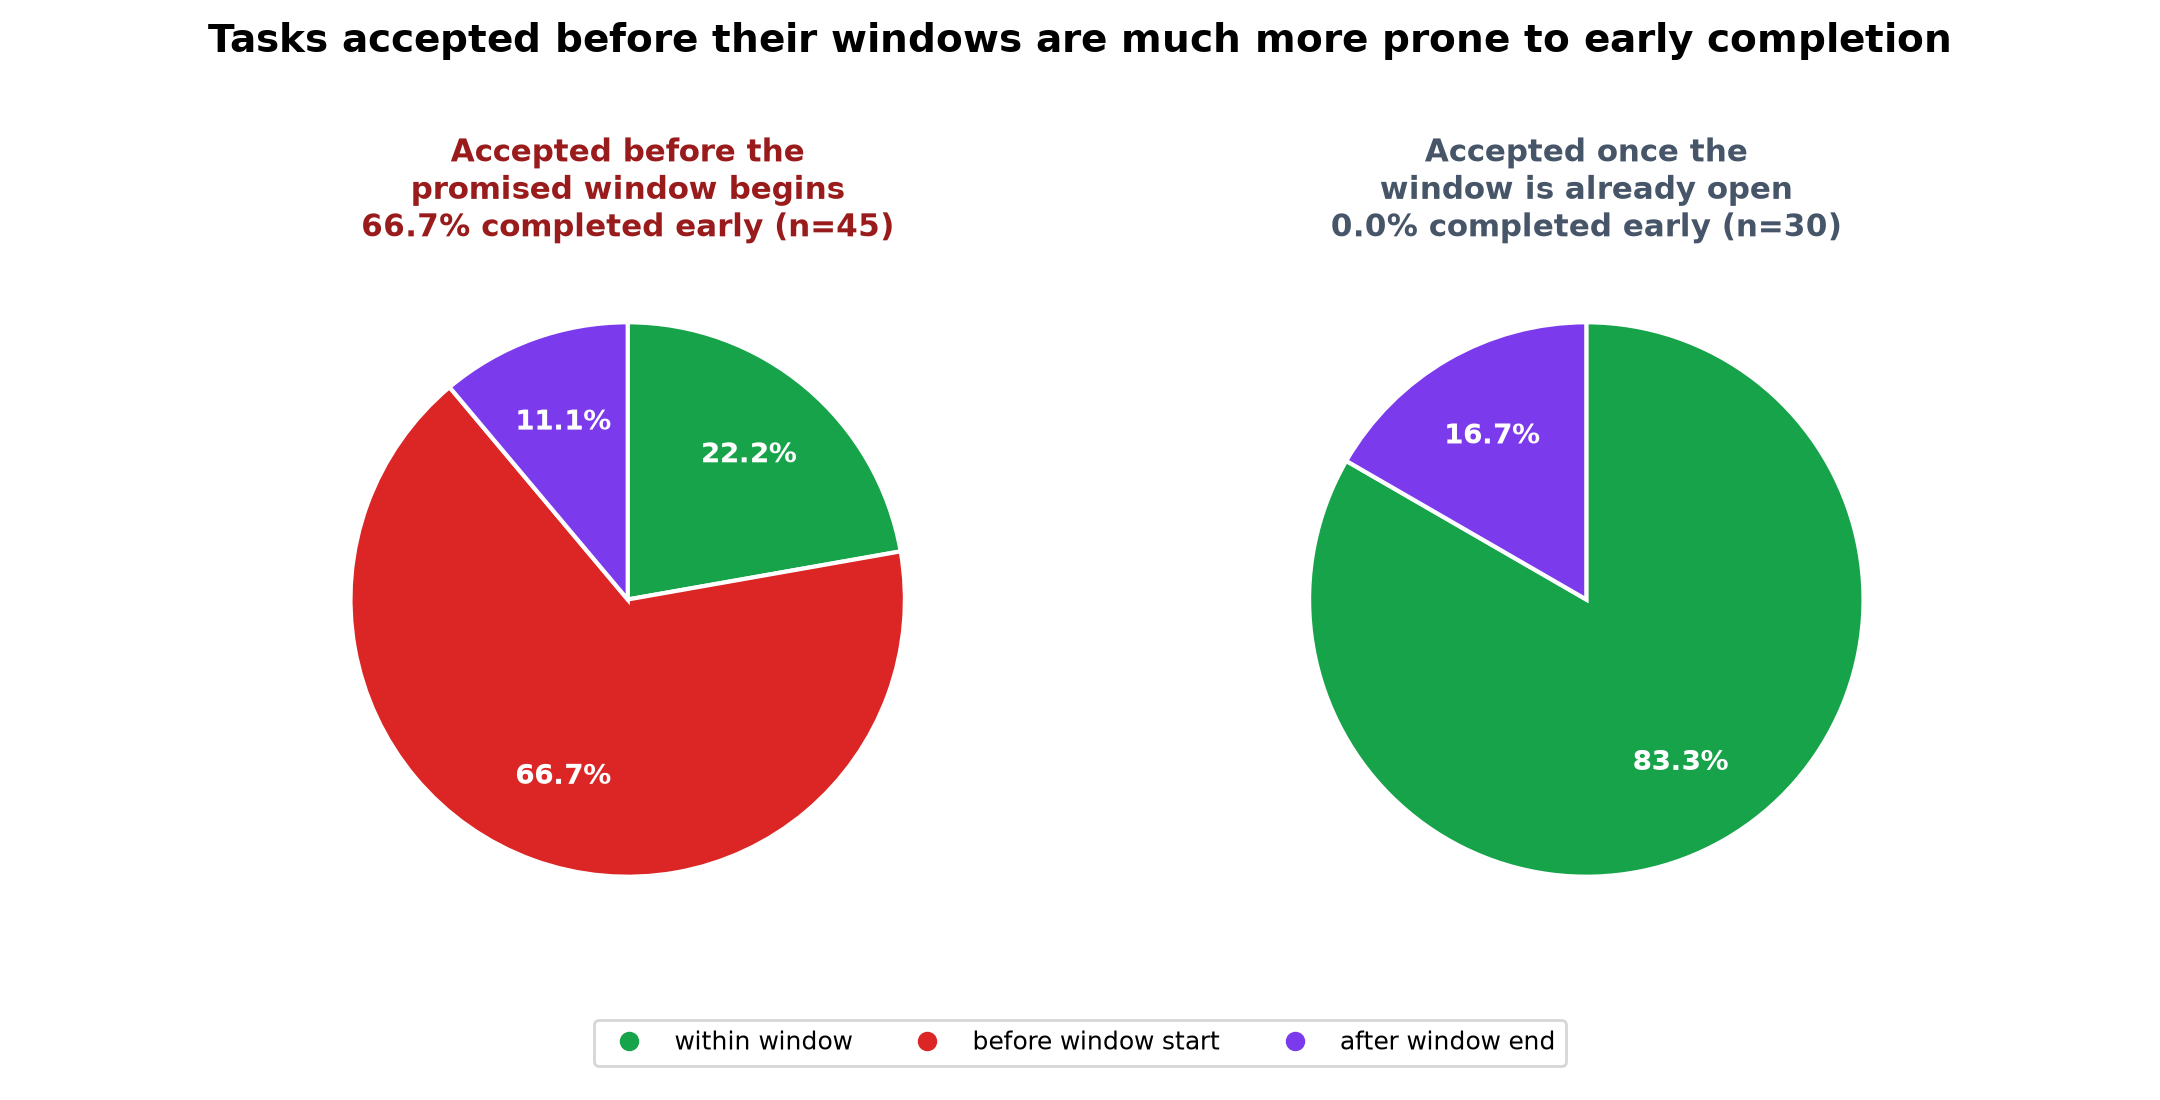

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path, parse_dates=['accept_time','time_window_start','time_window_end','pickup_time'])
# Compare pickup outcome classes for tasks accepted before their window starts and tasks accepted when their window is already open.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/pre_window_acceptance_early_completion.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "acceptance_timing_and_window_outcome",
  "insight": "Tasks accepted before their promised service windows begin are considerably more prone to being completed too early.",
  "insight_value": {
    "accepted_before_window_tasks": 45,
    "pre_window_early_completion_rate": "66.7%",
    "window_open_early_completion_rate": "0%"
  },
  "plot": {
    "plot_type": "acceptance_condition_window_outcome_pies",
    "title": "Pre-Window Acceptance and Early Pickup Completion",
    "file": "visualizations/pre_window_acceptance_early_completion.png",
    "description": "Two pies show the full pickup-outcome composition for pre-window and already-open-window acceptance conditions."
  },
  "question": "How does accepting a pickup task before versus after its promised service window begins relate to early pickup completion?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path, parse_dates=['accept_time','time_window_start','time_window_end','pickup_time'])\n# Compare pickup outcome classes for tasks accepted before their window starts and tasks accepted when their window is already open.",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "time_window_start",
    "task_id",
    "time_window_end"
  ]
}

### **Question 2**: How does pickup compliance differ for tasks with narrow, medium, and wide promised service windows?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

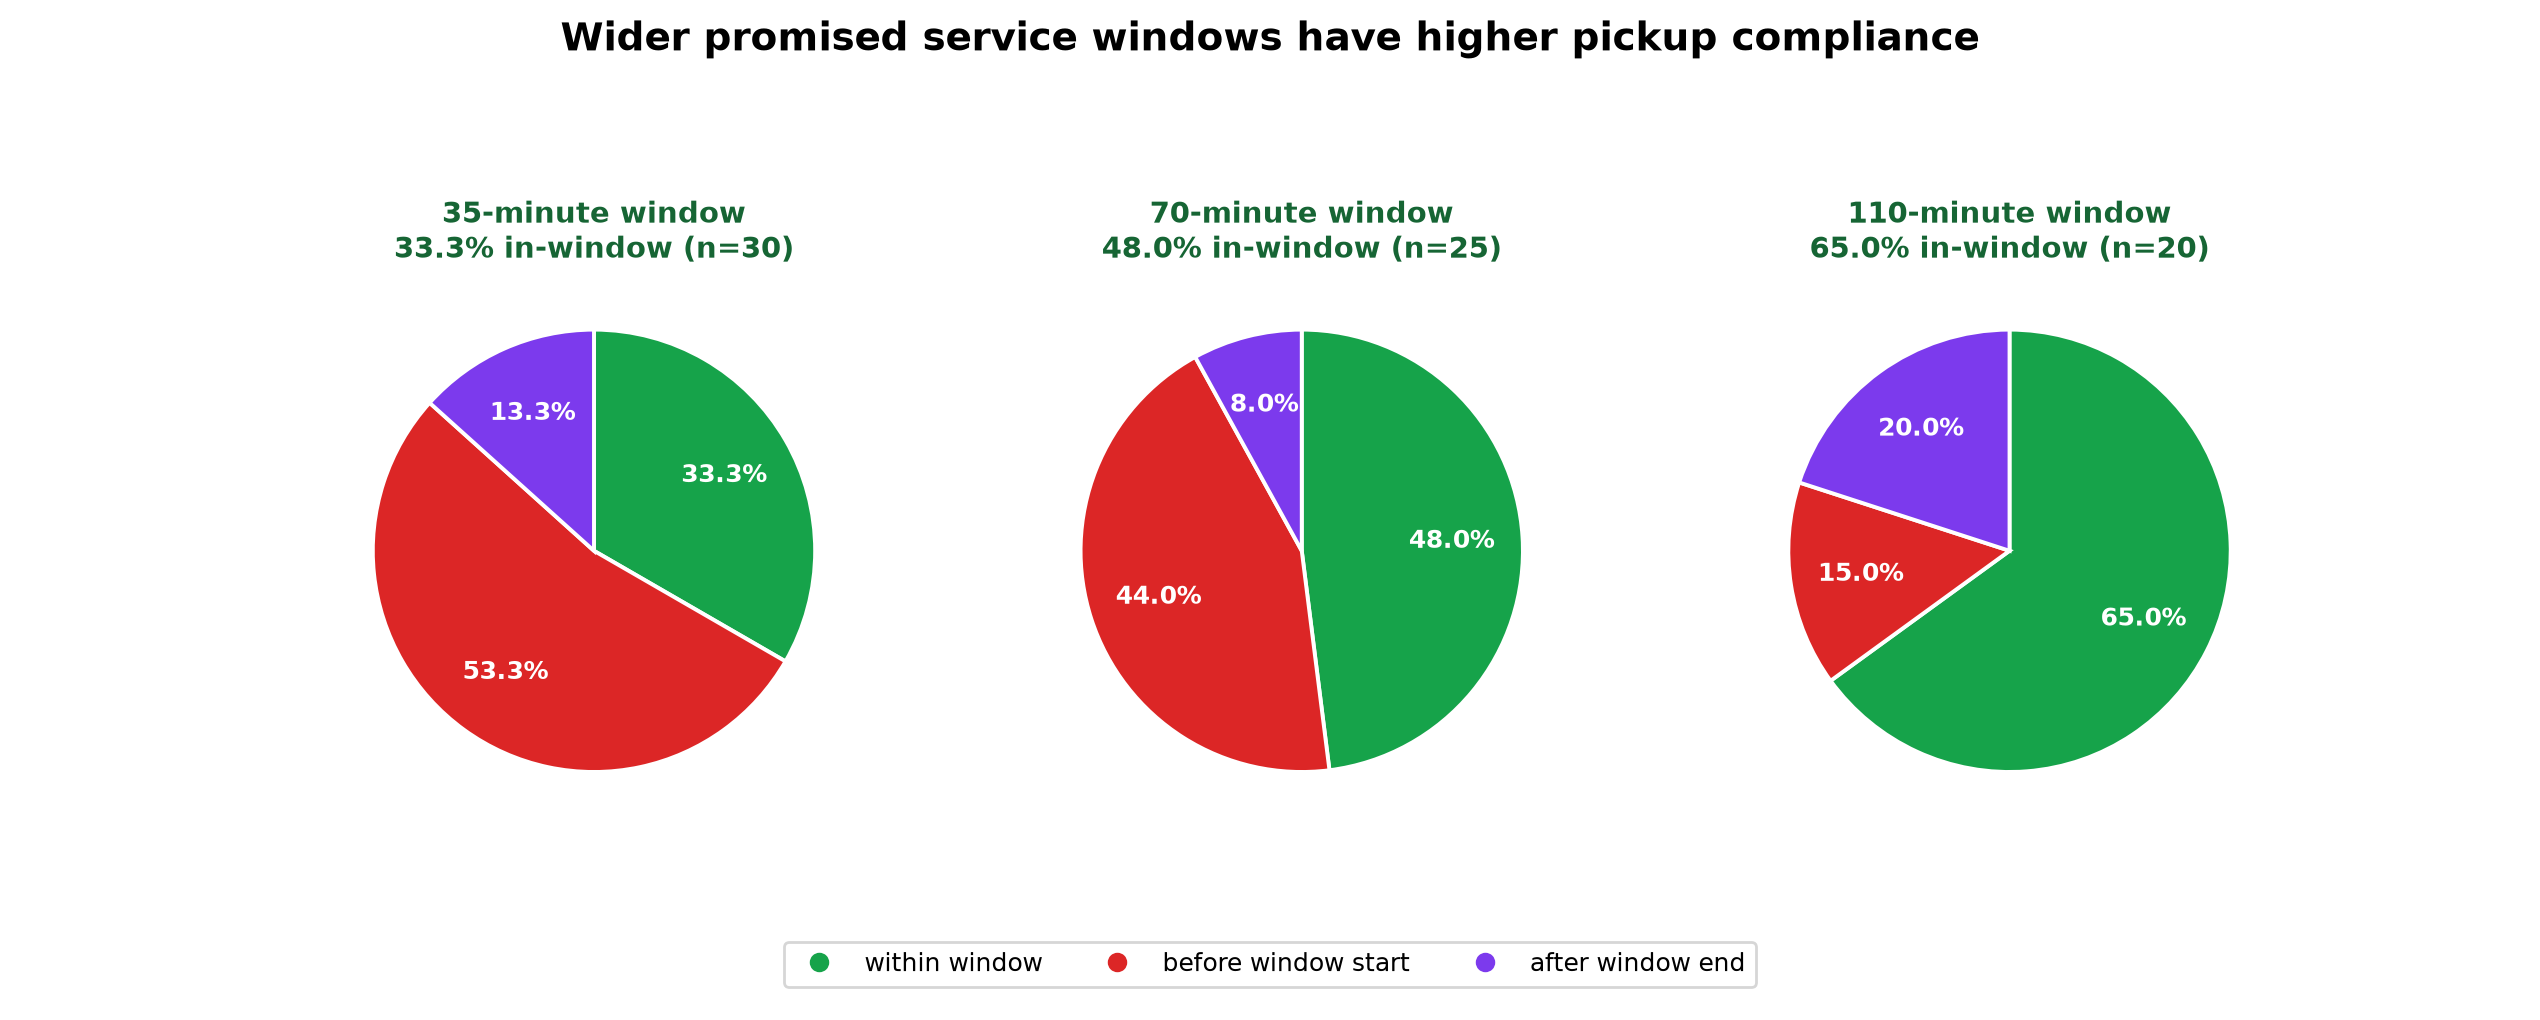

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path, parse_dates=['time_window_start','time_window_end','pickup_time'])
# Compute each promised window width, classify pickup_time as before/within/after its window, and compare compliance across widths.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/window_width_compliance.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "service_window_width_and_compliance",
  "insight": "Pickup tasks with longer promised service windows exhibit substantially higher compliance than tasks constrained by narrower windows.",
  "insight_value": {
    "35_min_window_compliance": "33.3%",
    "70_min_window_compliance": "48.0%",
    "110_min_window_compliance": "65.0%"
  },
  "plot": {
    "plot_type": "service_window_width_outcome_pies",
    "title": "Promised Window Width and Pickup Compliance",
    "file": "visualizations/window_width_compliance.png",
    "description": "Three pies show progressively higher in-window completion for wider service windows, with task counts explicit in each panel."
  },
  "question": "How does pickup compliance differ for tasks with narrow, medium, and wide promised service windows?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path, parse_dates=['time_window_start','time_window_end','pickup_time'])\n# Compute each promised window width, classify pickup_time as before/within/after its window, and compare compliance across widths.",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### **Question 3**: How do pickup-duration distributions differ across short-, medium-, and long-distance GPS travel segments?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

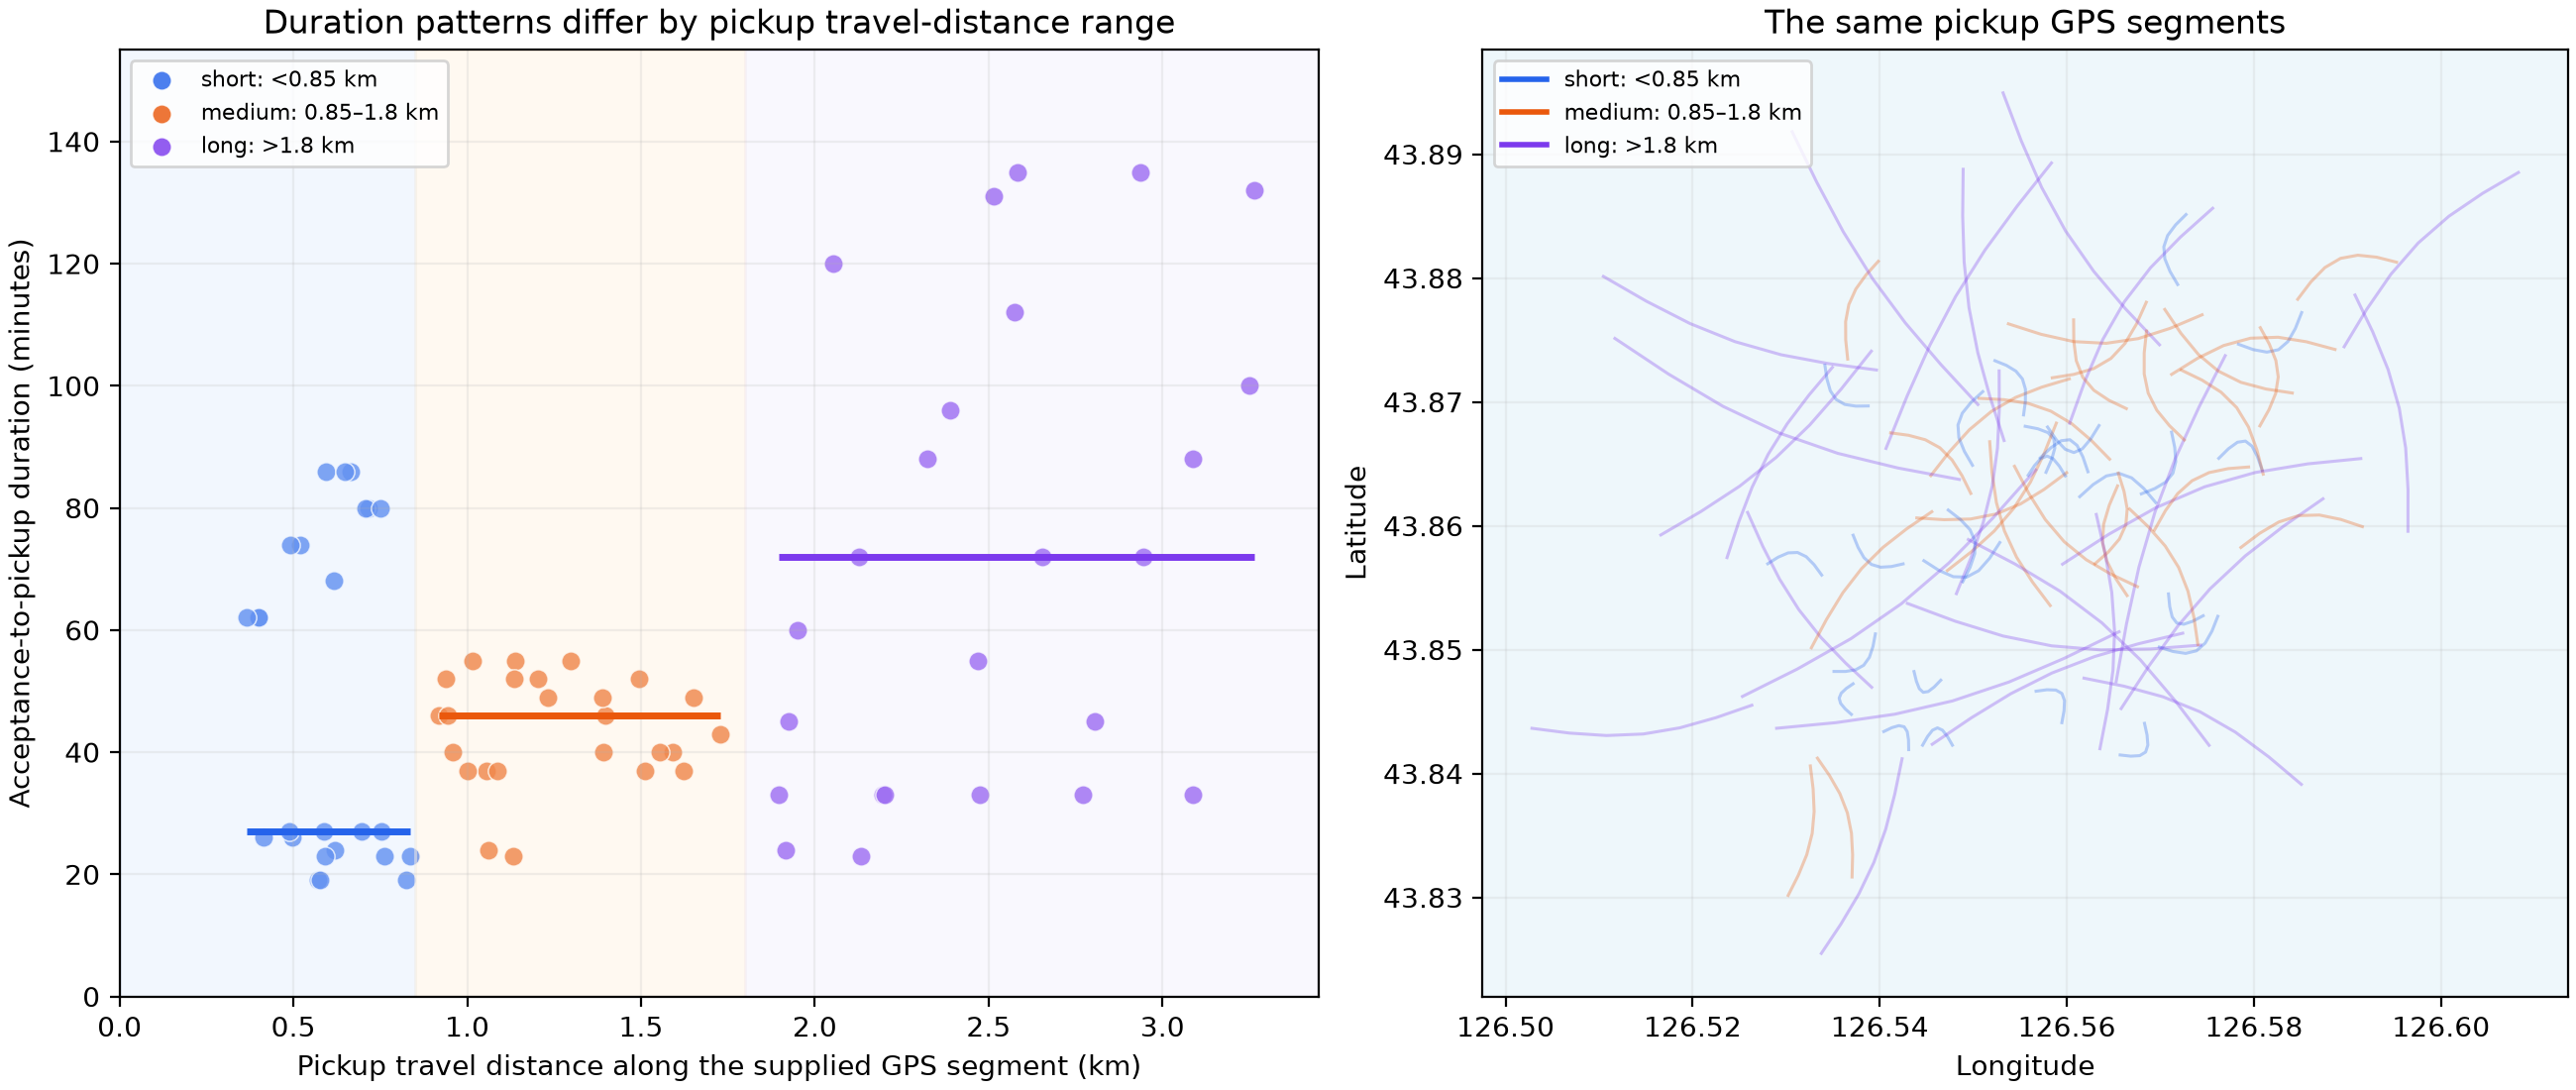

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path)
points = pd.read_csv(user_dataset_path, parse_dates=['gps_time'])
# Sum point-to-point GPS distances for each linked pickup segment, group tasks by the resulting distance, and compare their full acceptance-to-pickup duration distributions.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/distance_duration_patterns.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "travel_distance_and_pickup_duration_patterns",
  "insight": "Pickup duration does not increase uniformly with travel distance; instead, tasks exhibit distinct duration patterns across different distance ranges.",
  "insight_value": {
    "distance_ranges": [
      "short: under 0.85 km",
      "medium: 0.85–1.8 km",
      "long: over 1.8 km"
    ],
    "pattern": "nearby tasks are bimodal, middle-distance tasks are compact, and long-distance tasks have a broad slow tail"
  },
  "plot": {
    "plot_type": "distance_duration_scatter_and_gps_segment_map",
    "title": "Pickup Distance and Duration Patterns",
    "file": "visualizations/distance_duration_patterns.png",
    "description": "Task-level duration distributions and the corresponding GPS pickup segments show distinct rather than uniformly increasing distance-duration patterns."
  },
  "question": "How do pickup-duration distributions differ across short-, medium-, and long-distance GPS travel segments?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path)\npoints = pd.read_csv(user_dataset_path, parse_dates=['gps_time'])\n# Sum point-to-point GPS distances for each linked pickup segment, group tasks by the resulting distance, and compare their full acceptance-to-pickup duration distributions.",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "gps_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 8)

Pickup completion in this multi-courier sample depends on both timing and task constraints. Tasks accepted before their windows are disproportionately completed early, wider promised windows have higher compliance, and travel distance produces distinct duration regimes rather than a simple increasing relationship.